# Program 15: find out why relapse happens

**What:** run controlled experiments that separate the causes of relapse.

**How:** compare four conditions: (a) forget-class samples left in the buffer vs. purged; (b) the later task is *similar* to the forgotten class (for example forget "wolf", then learn "dog") vs. *dissimilar* (forget "wolf", then learn "truck"). Use CIFAR-100's superclasses to pick similar pairs. Measure relapse with both output accuracy and the probe.

**Why:** your method must target the real cause. This experiment also motivates each part of Relapse-Guard.

**Understanding note:** two routes to relapse. Buffer leakage is easy to fix by deleting data. Backward transfer from similar tasks is the hard one, and it is what the guard loss targets.

**Done when:** a small table shows relapse for all four conditions, and you can explain which cause is bigger.

## Where this fits (for a first-time reader)

Programs 12–14 showed *whether* forgotten knowledge comes back. This program asks *why*, using a small controlled experiment instead of a random stream: change one thing at a time and keep everything else identical.

**The experiment** (one class, "wolf", is forgotten):

```
learn task A (wolf + 9 other classes)  →  U wolf (BadTeacher)  →  learn ONE later task  →  did wolf come back?
                                                     │
                     buffer: wolf images PURGED or KEPT       later task: SIMILAR or DISSIMILAR to wolf
```

That's 2 × 2 = **4 conditions**. All four start from the **same** model right after `U wolf`, and the later task is trained with the same random seed, so the only differences are the two switches.

**The two suspected causes:**

| Cause | What happens | Easy to fix? |
|---|---|---|
| **buffer leakage** | wolf images stay in the DER++ buffer and get replayed **with their label** ("this is a wolf"), so the model is literally retrained on wolf | yes: delete them |
| **backward transfer** | learning wolf-like animals (fox, lion, tiger…) rebuilds features that also recognize wolves, even with no wolf image anywhere | no: this is what Relapse-Guard targets |

CIFAR-100 does not have "dog", so the similar task uses wolf's own superclass (*large carnivores*: bear, leopard, lion, tiger), plus *medium mammals* (fox, porcupine, possum, raccoon, skunk) and otter. The dissimilar task is furniture and vehicles.

## 1. Setup

- `task_a`: wolf plus 9 other classes (5 large mammals, so wolf is not trivially "the only animal", plus 4 unrelated classes).
- `similar` / `dissimilar`: the two possible later tasks, 10 classes each.
- DER++ and BadTeacher settings: the same as program 12.
- `seeds`: the whole experiment is repeated with 3 seeds and reported as mean ± spread. One seed alone could be luck.

**Time:** about 8 minutes per seed (task A, unlearning, 4 later tasks), so about 25 minutes. The seed-0 models are saved for program 16.

In [1]:
import gc, sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

# Reload the shared code, so edits to common/ are picked up even without restarting the kernel.
import importlib
import common.utils, common.data, common.models, common.train, common.derpp, common.badteacher, common.features, common.metrics
for module in (common.utils, common.data, common.models, common.train, common.derpp, common.badteacher, common.features, common.metrics):
    importlib.reload(module)

import copy
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader

from common.badteacher import badteacher_unlearn, make_bad_teacher
from common.data import IndexedSubset, SplitCIFAR100
from common.derpp import DERBuffer, train_one_epoch_derpp
from common.features import features_of, probe_accuracy
from common.models import resnet18_cifar
from common.utils import RESULTS_DIR, get_device, log_run, set_seed

SETTINGS = {
    "seeds": [0, 1, 2],
    "workers": 2,
    "forget": "wolf",
    "task_a": ["wolf", "camel", "cattle", "chimpanzee", "elephant", "kangaroo", "bus", "bicycle", "orchid", "apple"],
    "similar": ["bear", "leopard", "lion", "tiger", "fox", "porcupine", "possum", "raccoon", "skunk", "otter"],
    "dissimilar": ["bed", "chair", "couch", "table", "wardrobe", "lawn_mower", "rocket", "streetcar", "tank", "tractor"],
    # DER++ (program 06 / 12)
    "epochs": 5, "lr": 0.03, "batch_size": 32,
    "buffer_size": 2000, "replay_batch": 32, "alpha": 0.5, "beta": 0.5,
    # BadTeacher (program 09 / 12)
    "unlearn_lr": 1e-4, "unlearn_steps": 50, "forget_batch": 64, "retain_batch": 192,
    "min_forget": 64, "bad_teacher_seed": 0,
    "probe_folds": 5,
}
device = get_device()
print("device:", device)

device: cuda


## 2. Data and labels

Split CIFAR-100's usual tasks are not used here. Instead the three hand-picked groups of 10 classes are looked up by name. All 3,000 test images of these 30 classes go into GPU memory once.

In [2]:
data = SplitCIFAR100(seed=0, batch_size=SETTINGS["batch_size"], num_workers=SETTINGS["workers"])
lab = {name: data.class_names.index(name) for name in data.class_names}
A = np.array([lab[n] for n in SETTINGS["task_a"]])
SIM = np.array([lab[n] for n in SETTINGS["similar"]])
DIS = np.array([lab[n] for n in SETTINGS["dissimilar"]])
WOLF = lab[SETTINGS["forget"]]
LATER = {"similar": SIM, "dissimilar": DIS}

targets = np.array(data.test_set.targets)
test_idx = np.where(np.isin(targets, np.concatenate([A, SIM, DIS])))[0]
X = torch.stack([data.test_set[i][0] for i in test_idx]).to(device)
Y = targets[test_idx]
print(f"test images on GPU: {len(X)} (30 classes x 100)")
print("task A:     ", SETTINGS["task_a"])
print("similar:    ", SETTINGS["similar"])
print("dissimilar: ", SETTINGS["dissimilar"])

# The probe: wolf vs the other 9 task-A classes, 100 images each side (balanced, chance 50%).
rng_probe = np.random.RandomState(0)
wolf_rows = np.where(Y == WOLF)[0]
other_rows = rng_probe.choice(np.where(np.isin(Y, A) & (Y != WOLF))[0], len(wolf_rows), replace=False)
PROBE_ROWS = np.concatenate([wolf_rows, other_rows])
PROBE_Y = np.r_[np.ones(len(wolf_rows)), np.zeros(len(other_rows))]

test images on GPU: 3000 (30 classes x 100)
task A:      ['wolf', 'camel', 'cattle', 'chimpanzee', 'elephant', 'kangaroo', 'bus', 'bicycle', 'orchid', 'apple']
similar:     ['bear', 'leopard', 'lion', 'tiger', 'fox', 'porcupine', 'possum', 'raccoon', 'skunk', 'otter']
dissimilar:  ['bed', 'chair', 'couch', 'table', 'wardrobe', 'lawn_mower', 'rocket', 'streetcar', 'tank', 'tractor']


## 3. Measuring wolf

After each stage we measure four things about wolf, on its 100 test images:

| Measure | What it reads | Chance |
|---|---|---|
| **within-A accuracy** | the head, choosing among task A's 10 outputs: is a wolf image called "wolf"? | 10% |
| **wolf probability** | the head: average probability of "wolf" among task A's outputs | 10% |
| **class-IL accuracy** | the head, choosing among *all learned* outputs (10 or 20) | 10% → 5% |
| **probe** | the features: can a linear classifier tell wolf from the other 9 task-A classes? | 50% |

The first two are comparable across all stages (always 10 outputs), so relapse is measured with them. The probe measures whether the **features** still separate wolf, as in program 14.

In [3]:
@torch.no_grad()
def measure(model, learned):
    model.eval()
    logits = torch.cat([model(X[i:i + 1000]) for i in range(0, len(X), 1000)]).float().cpu()
    w = Y == WOLF
    la = logits[:, torch.from_numpy(A)]
    within_a = float((A[la.argmax(1).numpy()][w] == WOLF).mean())
    prob = float(torch.softmax(la, 1)[torch.from_numpy(w), list(A).index(WOLF)].mean())
    ll = logits[:, torch.from_numpy(np.asarray(learned))]
    cil = float((learned[ll.argmax(1).numpy()][w] == WOLF).mean())
    feats = features_of(model, X[torch.from_numpy(PROBE_ROWS).to(device)]).numpy()
    probe, _ = probe_accuracy(feats, PROBE_Y, folds=SETTINGS["probe_folds"], seed=0)
    return {"within_a": within_a, "wolf_prob": prob, "class_il": cil, "probe": probe}


def show(name, m):
    print(f"   {name:>26}: within-A {m['within_a']*100:5.1f}%  wolf prob {m['wolf_prob']*100:5.1f}%  "
          f"class-IL {m['class_il']*100:5.1f}%  probe {m['probe']*100:5.1f}%")


torch.manual_seed(0)
never = resnet18_cifar(num_classes=100).to(device)
never_m = measure(never, A)
del never
print("never-trained network (the floor):")
show("never-trained", never_m)

never-trained network (the floor):
                never-trained: within-A   0.0%  wolf prob  10.0%  class-IL   0.0%  probe  72.0%


## 4. The building blocks: learn, unlearn, copy the buffer

- `learn(labels)`: DER++ for 5 epochs on the training images of these 10 classes (program 06's loop).
- `unlearn_wolf()`: BadTeacher exactly as in program 12. Forget data = wolf's buffer images (topped up to 64 from the training set if fewer), retain data = the rest of the buffer.
- `snapshot` / `restore`: save the buffer's contents (which images, labels, stored logits) so that all four conditions start from the same buffer. Only the small arrays are copied, not the images.

In [4]:
def learn(model, buffer, labels, scaler):
    subset = IndexedSubset(data.train_set, data.train_indices(labels.tolist()))
    loader = DataLoader(subset, batch_size=SETTINGS["batch_size"], shuffle=True, num_workers=SETTINGS["workers"],
                        pin_memory=torch.cuda.is_available())
    optimizer = torch.optim.SGD(model.parameters(), lr=SETTINGS["lr"], momentum=0.9)
    for epoch in range(SETTINGS["epochs"]):
        losses, train_acc = train_one_epoch_derpp(model, loader, optimizer, buffer, scaler, device,
                                                  alpha=SETTINGS["alpha"], beta=SETTINGS["beta"],
                                                  replay_batch=SETTINGS["replay_batch"])
    del loader, optimizer
    gc.collect()
    return train_acc


def load_images(idx):
    return torch.stack([data.train_set[j][0] for j in idx])


def unlearn_wolf(model, buffer, rng, seed):
    forget_idx = buffer.indices[buffer.positions_of([WOLF])].tolist()
    from_buffer = len(forget_idx)
    if from_buffer < SETTINGS["min_forget"]:
        pool = sorted(set(data.train_indices([WOLF])) - set(forget_idx))
        forget_idx += rng.choice(pool, SETTINGS["min_forget"] - from_buffer, replace=False).tolist()
    forget_idx = np.array(forget_idx)
    n = len(buffer)
    retain_idx = buffer.indices[:n][buffer.labels[:n] != WOLF]
    fb, rb = SETTINGS["forget_batch"], SETTINGS["retain_batch"]
    sample_forget = lambda: load_images(rng.choice(forget_idx, fb, replace=len(forget_idx) < fb))
    sample_retain = lambda: load_images(rng.choice(retain_idx, min(rb, len(retain_idx)), replace=False))
    good = copy.deepcopy(model).eval()
    for p in good.parameters():
        p.requires_grad_(False)
    bad, bad_seed, fav = make_bad_teacher(100, load_images(forget_idx[:256]), [WOLF], SETTINGS["bad_teacher_seed"] + seed, device)
    badteacher_unlearn(model, good, bad, sample_forget, sample_retain, SETTINGS["unlearn_steps"], SETTINGS["unlearn_lr"], device)
    del good, bad
    torch.cuda.empty_cache()
    return from_buffer


def snapshot(buffer):
    return {"indices": buffer.indices.copy(), "labels": buffer.labels.copy(), "logits": buffer.logits.clone(),
            "n_kept": buffer.n_kept, "n_seen": buffer.n_seen}


def restore(snap):
    b = DERBuffer(SETTINGS["buffer_size"], dataset=data.train_set)
    b.indices, b.labels, b.logits = snap["indices"].copy(), snap["labels"].copy(), snap["logits"].clone()
    b.n_kept, b.n_seen = snap["n_kept"], snap["n_seen"]
    return b

## 5. Run the experiment

For each seed:
1. learn task A → measure ("before U");
2. `U wolf` with BadTeacher → measure ("after U");
3. for each of the 4 conditions, start again from the "after U" model and buffer: purge wolf from the buffer or not, learn the similar or dissimilar task → measure ("end").

Seed 0's models are saved for program 16: `15_before_unlearn.pt` (model + buffer), `15_after_unlearn_model.pt`, and one `15_<buffer>_<task>_model.pt` per condition.

In [5]:
CONDITIONS = [("purged", "similar"), ("purged", "dissimilar"), ("kept", "similar"), ("kept", "dissimilar")]
results = []          # one dict per seed
start = time.time()
for seed in SETTINGS["seeds"]:
    print(f"=== seed {seed}")
    set_seed(seed)
    rng = np.random.RandomState(seed)
    model = resnet18_cifar(num_classes=100).to(device)
    scaler = torch.amp.GradScaler(enabled=device.type == "cuda")
    buffer = DERBuffer(SETTINGS["buffer_size"], dataset=data.train_set)

    acc = learn(model, buffer, A, scaler)
    r = {"before": measure(model, A)}
    n_wolf = len(buffer.positions_of([WOLF]))
    print(f"learned task A (train acc {acc*100:.1f}%), wolf images in buffer: {n_wolf}  ({time.time()-start:.0f}s)")
    show("before U", r["before"])
    if seed == SETTINGS["seeds"][0]:
        torch.save({"model": model.state_dict(), "buffer": snapshot(buffer),
                    "labels": {"A": A.tolist(), "WOLF": WOLF, "SIM": SIM.tolist(), "DIS": DIS.tolist()}},
                   RESULTS_DIR / "15_before_unlearn.pt")

    from_buffer = unlearn_wolf(model, buffer, rng, seed)
    r["after"] = measure(model, A)
    show(f"after U ({from_buffer} wolf imgs)", r["after"])
    after_state = copy.deepcopy(model.state_dict())
    after_buffer = snapshot(buffer)
    if seed == SETTINGS["seeds"][0]:
        torch.save(after_state, RESULTS_DIR / "15_after_unlearn_model.pt")

    for buf_mode, later in CONDITIONS:
        model.load_state_dict(after_state)
        buf = restore(after_buffer)
        if buf_mode == "purged":
            buf.remove([WOLF])
        set_seed(seed + 100)                     # the same randomness for all four conditions
        learn(model, buf, LATER[later], scaler)
        key = f"{buf_mode}_{later}"
        r[key] = measure(model, np.concatenate([A, LATER[later]]))
        show(f"end: buffer {buf_mode}, {later}", r[key])
        if seed == SETTINGS["seeds"][0]:
            torch.save(model.state_dict(), RESULTS_DIR / f"15_{key}_model.pt")
        del buf
    results.append(r)
    del model, buffer, after_state
    gc.collect()
    torch.cuda.empty_cache()
    print(f"   ({time.time()-start:.0f}s)")
minutes = (time.time() - start) / 60
print(f"\ndone in {minutes:.1f} min")

=== seed 0


learned task A (train acc 63.8%), wolf images in buffer: 203  (75s)
                     before U: within-A  60.0%  wolf prob  49.0%  class-IL  60.0%  probe  84.0%


      after U (203 wolf imgs): within-A  59.0%  wolf prob  23.5%  class-IL  59.0%  probe  85.0%


   end: buffer purged, similar: within-A   0.0%  wolf prob   6.9%  class-IL   0.0%  probe  89.0%


   end: buffer purged, dissimilar: within-A   0.0%  wolf prob   5.9%  class-IL   0.0%  probe  82.5%


    end: buffer kept, similar: within-A  73.0%  wolf prob  48.5%  class-IL  17.0%  probe  85.5%


... (10 outputs left out)

   end: buffer purged, similar: within-A   0.0%  wolf prob   8.6%  class-IL   0.0%  probe  84.0%


   end: buffer purged, dissimilar: within-A   0.0%  wolf prob   7.1%  class-IL   0.0%  probe  88.0%


    end: buffer kept, similar: within-A  74.0%  wolf prob  52.8%  class-IL  40.0%  probe  89.5%


   end: buffer kept, dissimilar: within-A  50.0%  wolf prob  34.8%  class-IL  38.0%  probe  88.5%
   (1168s)

done in 19.5 min


## 6. The four-condition table

**Relapse** = value at the end − value right after `U` (positive = wolf came back). Mean ± spread over the 3 seeds.

Reading it:
- **kept − purged** (same later task) = how much **buffer leakage** adds.
- **similar − dissimilar** (same buffer) = how much **backward transfer** from similar classes adds.

In [6]:
MEASURES = [("within_a", "within-A acc"), ("wolf_prob", "wolf prob"), ("probe", "probe")]


def stat(key, measure_name, rise=True):
    vals = np.array([r[key][measure_name] - (r["after"][measure_name] if rise else 0) for r in results]) * 100
    return vals.mean(), vals.std()


print("Wolf at each stage (mean over seeds, %):")
print(f"{'stage':>22} " + " ".join(f"{label:>14}" for _, label in MEASURES))
for key, name in [("before", "before U"), ("after", "after U")] + [(f"{b}_{l}", f"end: {b}, {l}") for b, l in CONDITIONS]:
    print(f"{name:>22} " + " ".join(f"{stat(key, m, rise=False)[0]:13.1f}%" for m, _ in MEASURES))
print(f"{'never-trained':>22} " + " ".join(f"{never_m[m]*100:13.1f}%" for m, _ in MEASURES))

print("\nRELAPSE = end - after U (percentage points, mean ± spread over seeds):")
print(f"{'buffer':>8} {'later task':>11} " + " ".join(f"{label:>16}" for _, label in MEASURES))
table = {}
for b, l in CONDITIONS:
    row = [stat(f"{b}_{l}", m) for m, _ in MEASURES]
    table[(b, l)] = row
    print(f"{b:>8} {l:>11} " + " ".join(f"{mu:+9.1f} ± {sd:4.1f}" for mu, sd in row))

print("\nEffect of each cause on within-A relapse (points):")
leak = np.mean([table[("kept", l)][0][0] - table[("purged", l)][0][0] for l in ("similar", "dissimilar")])
transfer = np.mean([table[(b, "similar")][0][0] - table[(b, "dissimilar")][0][0] for b in ("purged", "kept")])
print(f"   buffer leakage   (kept - purged, averaged over later tasks):     {leak:+.1f}")
print(f"   backward transfer (similar - dissimilar, averaged over buffers): {transfer:+.1f}")

Wolf at each stage (mean over seeds, %):
                 stage   within-A acc      wolf prob          probe
              before U          66.3%          53.5%          87.0%
               after U          60.7%          25.9%          88.0%
  end: purged, similar           0.0%           7.7%          85.8%
end: purged, dissimilar           0.0%           6.3%          85.7%
    end: kept, similar          69.7%          45.4%          88.0%
 end: kept, dissimilar          55.3%          39.8%          87.3%
         never-trained           0.0%          10.0%          72.0%

RELAPSE = end - after U (percentage points, mean ± spread over seeds):
  buffer  later task     within-A acc        wolf prob            probe
  purged     similar     -60.7 ±  3.1     -18.3 ±  2.3      -2.2 ±  4.4
  purged  dissimilar     -60.7 ±  3.1     -19.6 ±  2.5      -2.3 ±  0.6
    kept     similar      +9.0 ±  4.1     +19.5 ±  9.6      +0.0 ±  0.4
    kept  dissimilar      -5.3 ±  7.1     +13.9 ±  3.2

## 7. The picture

Left: within-A wolf accuracy before `U`, after `U`, and at the end of each condition. Right: the relapse (rise after `U`) of the head's within-A accuracy and of the probe, for the four conditions.

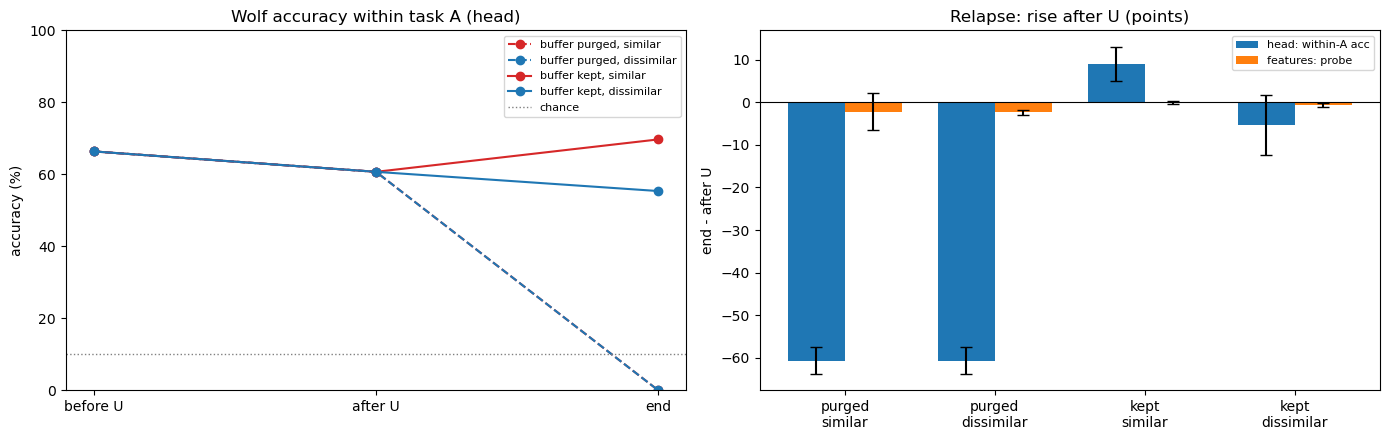

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
for b, l in CONDITIONS:
    ys = [np.mean([r[k]["within_a"] for r in results]) * 100 for k in ("before", "after", f"{b}_{l}")]
    ax.plot(["before U", "after U", "end"], ys, marker="o", label=f"buffer {b}, {l}",
            ls="-" if b == "kept" else "--", color="tab:red" if l == "similar" else "tab:blue")
ax.axhline(10, color="gray", ls=":", lw=1, label="chance")
ax.set(title="Wolf accuracy within task A (head)", ylabel="accuracy (%)", ylim=(0, 100))
ax.legend(fontsize=8)

ax = axes[1]
names = [f"{b}\n{l}" for b, l in CONDITIONS]
x = np.arange(len(CONDITIONS))
for k, (m, label) in enumerate([("within_a", "head: within-A acc"), ("probe", "features: probe")]):
    idx = [mm for mm, _ in MEASURES].index(m)
    mus = [table[c][idx][0] for c in CONDITIONS]
    sds = [table[c][idx][1] for c in CONDITIONS]
    ax.bar(x + (k - 0.5) * 0.38, mus, 0.38, yerr=sds, capsize=4, label=label)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x, names)
ax.set(title="Relapse: rise after U (points)", ylabel="end - after U")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "15_relapse_causes.png", dpi=120)
plt.show()

## 8. Log the run

In [8]:
log_run("15_relapse_causes", SETTINGS,
        {"never_trained": {k: round(v, 4) for k, v in never_m.items()},
         "per_seed": [{stage: {k: round(v, 4) for k, v in m.items()} for stage, m in r.items()} for r in results],
         "relapse_mean": {f"{b}_{l}": {m: round(table[(b, l)][i][0], 2) for i, (m, _) in enumerate(MEASURES)}
                          for b, l in CONDITIONS},
         "effect_buffer_leakage": round(float(leak), 2), "effect_backward_transfer": round(float(transfer), 2),
         "minutes": round(minutes, 1)})
print("logged to", RESULTS_DIR / "runs.jsonl")
del X
torch.cuda.empty_cache()

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. Did `U wolf` bring wolf's within-A accuracy near chance? And the probe: did it drop as much as the head?
2. Buffer kept vs purged: how much relapse does buffer leakage cause? Is deleting the data enough to stop it?
3. Similar vs dissimilar later task, with the buffer purged: does learning wolf-like animals bring wolf back with no wolf image anywhere?
4. Which cause is bigger? Which one would a simple fix (program 17) solve, and which one needs the guard (program 18)?
5. Head vs probe: in which conditions do the features recover more than the head (or the other way round)?